In [37]:
#Task 1: Data Loading and Initial Inspection
#Cell 1: Imports and load data
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")

url = "https://raw.githubusercontent.com/datasciencedojo/datasets/refs/heads/master/titanic.csv"
df = pd.read_csv(url)
print("Shape:", df.shape)

Shape: (891, 12)


In [38]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [39]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [40]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [41]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [42]:
#Task 2: Handling Missing Values

cabin_missing_pct = df["Cabin"].isnull().mean()*100
print(f"Missing values in cabin:{cabin_missing_pct:.2f}%")

Missing values in cabin:77.10%


In [43]:
df = df.drop(columns=["Cabin"])
df.columns.tolist()

['PassengerId',
 'Survived',
 'Pclass',
 'Name',
 'Sex',
 'Age',
 'SibSp',
 'Parch',
 'Ticket',
 'Fare',
 'Embarked']

In [44]:
embarked_mode = df["Embarked"].mode()[0]
print("Most frequent port:",embarked_mode)

df["Embarked"] = df["Embarked"].fillna(embarked_mode)
print("Missing Embarked:", df["Embarked"].isnull().sum())

Most frequent port: S
Missing Embarked: 0


In [45]:
age_median = df["Age"].median()
print("Median age:",age_median)
df["Age"] = df["Age"].fillna(age_median)
print("Missing Age:",df["Age"].isnull().sum())

Median age: 28.0
Missing Age: 0


In [46]:
df.isnull().sum()

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64

Overall survival rate: 38.38%


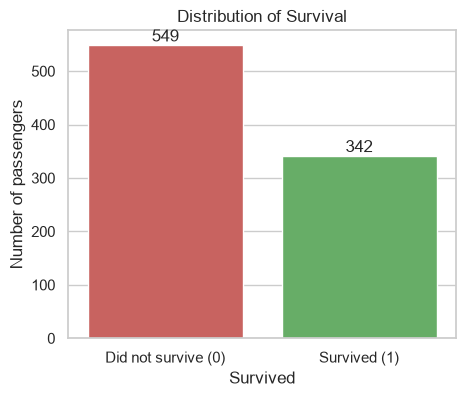

In [47]:
#Task 3: Univariate Analysis
survival_rate = df["Survived"].mean() * 100
print(f"Overall survival rate: {survival_rate:.2f}%")

plt.figure(figsize=(5, 4))
ax = sns.countplot(data=df, x="Survived", hue="Survived",
                   palette=["#d9534f", "#5cb85c"], legend=False)
ax.set_xticks([0, 1])
ax.set_xticklabels(["Did not survive (0)", "Survived (1)"])
for c in ax.containers:
    ax.bar_label(c)
plt.title("Distribution of Survival")
plt.ylabel("Number of passengers")
plt.show()

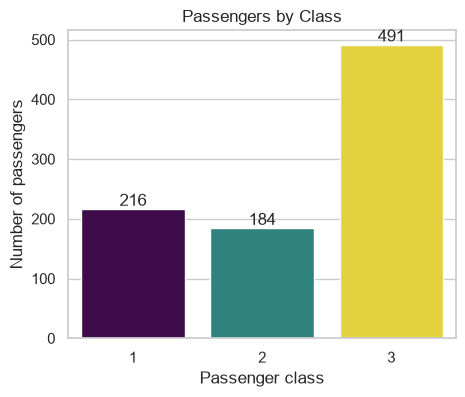

Pclass
3    491
1    216
2    184
Name: count, dtype: int64
Class with most passengers: 3


In [48]:
plt.figure(figsize=(5, 4))
ax = sns.countplot(data=df, x="Pclass", hue="Pclass", palette="viridis", legend=False)
for c in ax.containers:
    ax.bar_label(c)
plt.title("Passengers by Class")
plt.xlabel("Passenger class")
plt.ylabel("Number of passengers")
plt.show()

print(df["Pclass"].value_counts())
print("Class with most passengers:", df["Pclass"].value_counts().idxmax())

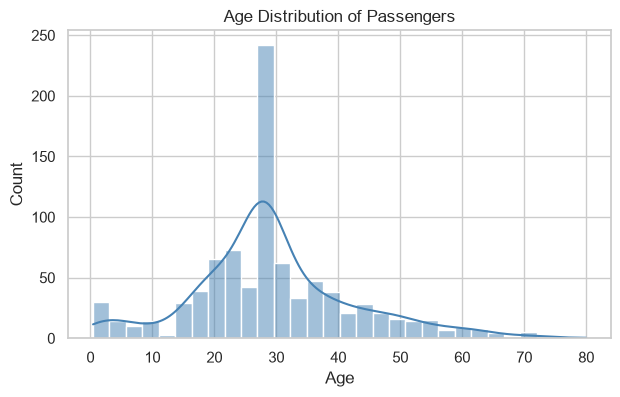

In [49]:
plt.figure(figsize=(7, 4))
sns.histplot(df["Age"], bins=30, kde=True, color="steelblue")
plt.title("Age Distribution of Passengers")
plt.xlabel("Age")
plt.ylabel("Count")
plt.show()

,Did not survive,Survived
Sex,,
female,81,233
male,468,109


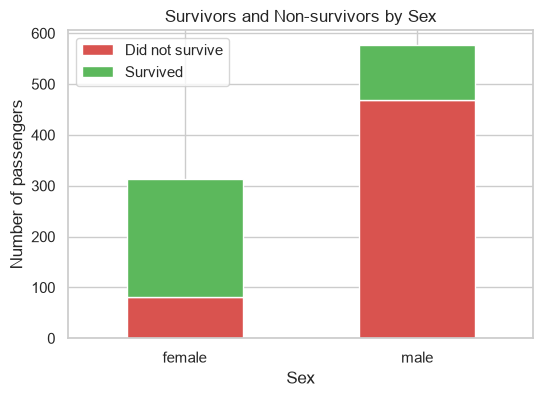

Sex
female    74.20
male      18.89
Name: Survived, dtype: float64


In [50]:
# Task 4: Bivariate and Multivariate Analysis
ct_sex = pd.crosstab(df["Sex"], df["Survived"])
ct_sex.columns = ["Did not survive", "Survived"]
display(ct_sex)

ct_sex.plot(kind="bar", stacked=True, color=["#d9534f", "#5cb85c"], figsize=(6, 4))
plt.title("Survivors and Non-survivors by Sex")
plt.ylabel("Number of passengers")
plt.xticks(rotation=0)
plt.show()

print((df.groupby("Sex")["Survived"].mean() * 100).round(2))


Pclass
1    62.96
2    47.28
3    24.24
Name: Survived, dtype: float64


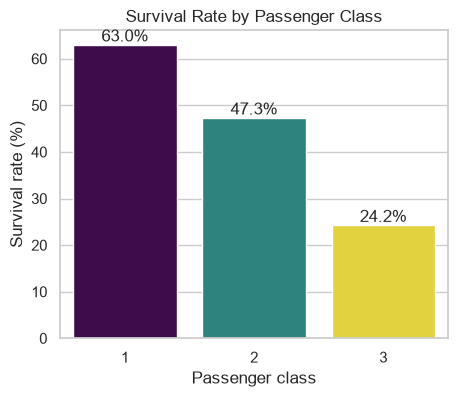

In [51]:
class_survival = df.groupby("Pclass")["Survived"].mean() * 100
print(class_survival.round(2))

plt.figure(figsize=(5, 4))
ax = sns.barplot(x=class_survival.index, y=class_survival.values,
                 hue=class_survival.index, palette="viridis", legend=False)
for c in ax.containers:
    ax.bar_label(c, fmt="%.1f%%")
plt.title("Survival Rate by Passenger Class")
plt.xlabel("Passenger class")
plt.ylabel("Survival rate (%)")
plt.show()

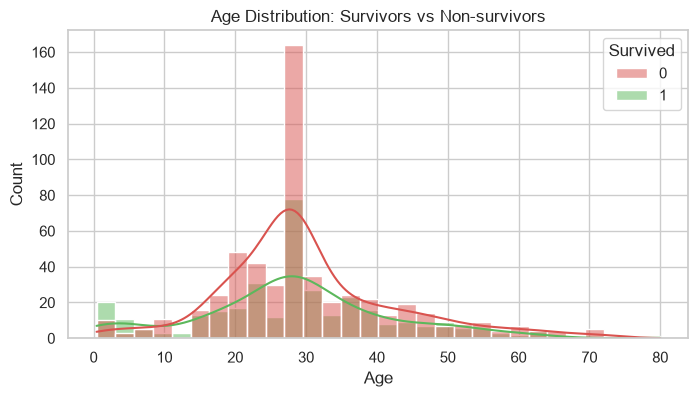

               survival_rate  count
Age                                
Child (0-12)           0.580     69
Teen (13-18)           0.429     70
Adult (19-60)          0.366    730
Senior (60+)           0.227     22


In [52]:
plt.figure(figsize=(8, 4))
sns.histplot(data=df, x="Age", hue="Survived", bins=30, kde=True,
             multiple="layer", palette={0: "#d9534f", 1: "#5cb85c"}, alpha=0.5)
plt.title("Age Distribution: Survivors vs Non-survivors")
plt.show()

age_groups = pd.cut(df["Age"], bins=[0, 12, 18, 60, 100],
                    labels=["Child (0-12)", "Teen (13-18)", "Adult (19-60)", "Senior (60+)"])
print(df.groupby(age_groups, observed=True)["Survived"]
        .agg(["mean", "count"])
        .rename(columns={"mean": "survival_rate"})
        .round(3))

Pclass,1,2,3
Embarked,,,
C,50.6,10.1,39.3
Q,2.6,3.9,93.5
S,20.0,25.4,54.6


Sex,female,male
Pclass,,
1,96.8,36.9
2,92.1,15.7
3,50.0,13.5


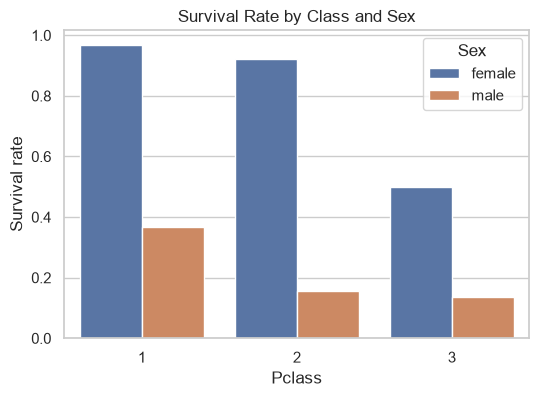

In [53]:
# Class mix at each port (% of passengers)
display((pd.crosstab(df["Embarked"], df["Pclass"], normalize="index") * 100).round(1))

# Survival rate by class and sex
pivot = df.pivot_table(values="Survived", index="Pclass", columns="Sex", aggfunc="mean") * 100
display(pivot.round(1))

plt.figure(figsize=(6, 4))
sns.barplot(data=df, x="Pclass", y="Survived", hue="Sex", errorbar=None)
plt.title("Survival Rate by Class and Sex")
plt.ylabel("Survival rate")
plt.show()

# Task 5: Conclusion and Insights

The strongest predictors of survival were **sex**, **passenger class**, and **age**. Women survived at about 74% versus about 19% for men, reflecting the "women and children first" evacuation order. Survival also fell steadily with class (about 63% in 1st, 47% in 2nd, 24% in 3rd), and children had the best survival odds (about 58%) while passengers over 60 had the worst. The higher survival at Cherbourg appears to come from its larger share of 1st-class passengers rather than from the port itself.